# 1 · Imagery discovery
`1_Planet_API_imagery_discovery.ipynb` · **Workflow:** 1 · Imagery discovery → 2 · Data preparation → 3 · NDVI analysis

Discover and inspect the Planet imagery that exists for the Pará area of interest (AOI) before anything is downloaded or analysed.

- Authenticate with the Planet API
- Define the area of interest
- Search for available imagery
- Inspect metadata, dates, cloud cover, assets and image availability
- Identify suitable scenes or collections

Separating discovery from processing makes it easier to verify that suitable data exist before downloading or analysing them.
Searching metadata is free; downloading costs time and account quota.

**Needs:** a Planet API key (typed at run time) · `pip install requests pandas` · **Output:** `no output as a paying account is need to download this data --> finding another solution -->  Sentinel Hub and not "api.planet.com" (justification in the following notebook)

## 1.1 Authenticate
The Data API uses HTTP Basic authentication: the API key is the user name, the password is empty.
`getpass` keeps the key out of the notebook file, its outputs and Git. An empty key fails immediately instead of returning a confusing HTTP 401 later.

In [1]:
from getpass import getpass

import pandas as pd
import requests
from IPython.display import Image, Markdown, display

QUICK_SEARCH_URL = "https://api.planet.com/data/v1/quick-search"

PLANET_API_KEY = getpass("Planet API key (input hidden): ").strip()
if not PLANET_API_KEY:
    raise ValueError("An API key is required to query the Planet Data API.")

## 1.2 Area of interest
A closed GeoJSON polygon in **longitude, latitude** order: the 568 km² rectangle `[-52.4825, -6.8735, -52.26725, -6.65775]` (west, south, east, north) taken from the Copernicus Data Space browser.

In [2]:
AOI = {
    "type": "Polygon",
    "coordinates": [[
        [-52.4825, -6.8735], [-52.4825, -6.65775],
        [-52.26725, -6.65775], [-52.26725, -6.8735],
        [-52.4825, -6.8735],
    ]],
}

## 1.3 Search for imagery
The search is limited to the 76 scene IDs given for the task (2016-2026) **and** to scenes that intersect the AOI.
All three Planet item types are listed because a scene ID only exists in one of them. A quick search answers in one request (no saved search needed); the timeout is 15 s to connect and 60 s to read.

In [3]:
REQUESTED_SCENE_IDS = [
    '20160816_125717_0e0d', '20160816_125718_0e0d', '20160816_125719_0e0d',
    '20160816_125816_0e0f', '20160816_125817_0e3a', '20160816_125817_0e0f',
    '20160816_125818_0e0f', '20160816_125819_0e3a', '20160816_125819_0e0f',
    '20160816_125820_0e3a', '20160816_125821_0e0f', '20160816_125821_0e3a',
    '20160816_125828_0e16', '20160816_125829_0e16', '20160816_125831_0e16',
    '20160816_125832_0e16', '20170622_130057_1026', '20170622_130058_1026',
    '20170622_130100_1026', '20170622_130101_1026', '20170622_130102_1026',
    '20170622_130148_1024', '20170622_130149_1024', '20170622_130151_1024',
    '20170622_130152_1024', '20170622_130153_1024', '20200709_131451_0e19',
    '20200709_131452_0e19', '20200709_131453_0e19', '20200709_131454_0e19',
    '20200709_131455_0e19', '20200709_134256_01_105c', '20200709_134257_89_105c',
    '20200709_134259_76_105c', '20210622_130016_76_2440', '20210622_130019_06_2440',
    '20210622_130021_37_2440', '20210622_130136_01_2429', '20210622_130138_31_2429',
    '20210622_135008_90_2419', '20210622_135011_38_2419', '20210622_135013_86_2419',
    '20220705_125542_65_242d', '20220705_125544_94_242d', '20220705_125547_24_242d',
    '20220705_132656_22_2482', '20220705_132658_50_2482', '20220705_132700_78_2482',
    '20230625_133059_08_2438', '20230625_133101_19_2438', '20230625_133103_30_2438',
    '20230625_133150_27_2495', '20230625_133152_41_2495', '20230625_133154_55_2495',
    '20240729_135811_12_24f5', '20240729_135813_35_24f5', '20240729_135815_59_24f5',
    '20240729_135949_11_24e0', '20240729_135951_35_24e0', '20240729_135953_59_24e0',
    '20250721_141153_79_251c', '20250721_141156_03_251c', '20250721_141640_52_252e',
    '20250721_141642_63_252e', '20250721_141644_73_252e', '20260802_135033_78_254d',
    '20260802_135035_88_254d', '20260802_135037_98_254d', '20260802_142722_38_253d',
    '20260802_142724_35_253d', '20260802_142726_32_253d', '20260802_143448_16_2409',
    '20260802_143449_97_2409', '20260802_143451_78_2409', '20260802_143617_56_24db',
    '20260802_143621_57_24db',
]


query = {
    "item_types": ["PSScene", "SkySatCollect", "PelicanScene"],
    "filter": {
        "type": "AndFilter",
        "config": [
            {"type": "GeometryFilter", "field_name": "geometry", "config": AOI},
            {"type": "StringInFilter", "field_name": "id", "config": REQUESTED_SCENE_IDS},
        ],
    },
}

response = requests.post(QUICK_SEARCH_URL, json=query, auth=(PLANET_API_KEY, ""), timeout=(15, 60))
if response.status_code == 401:
    raise PermissionError("Planet rejected the API key (HTTP 401). Check the key and account access.")
response.raise_for_status()

features = response.json().get("features", [])
print(f"Returned {len(features)} of {len(REQUESTED_SCENE_IDS)} requested scenes.")

Returned 76 of 76 requested scenes.


## 1.4 Inspect metadata
One row per scene: acquisition time, cloud cover, quality category, download permissions and links. `.get()` is used throughout because item types expose different properties.
An empty result is reported as a message (check account access, key and AOI), not as an error.

In [4]:
records = []
for feature in features:
    props, links = feature.get("properties", {}), feature.get("_links", {})
    records.append({
        "id": feature.get("id"),
        "item_type": feature.get("item_type") or props.get("item_type"),
        "acquired": props.get("acquired"),
        "cloud_percent": props.get("cloud_percent"),
        "cloud_cover": props.get("cloud_cover"),
        "quality_category": props.get("quality_category"),
        "thumbnail": links.get("thumbnail"),
        "item_url": links.get("_self"),
        "assets_url": links.get("assets"),
        "permissions": feature.get("_permissions"),
    })

scenes = pd.DataFrame(records)
if scenes.empty:
    display(Markdown("No scenes were returned for this AOI. Check account access, API key and AOI coordinates."))
else:
    display(scenes.drop(columns=["thumbnail"]).sort_values("acquired", na_position="last").reset_index(drop=True))

,id,item_type,acquired,cloud_percent,cloud_cover,quality_category,item_url,assets_url,permissions
0,20160816_125717_0e0d,PSScene,2016-08-16T12:57:17.67708Z,NaN,0.0,test,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
1,20160816_125718_0e0d,PSScene,2016-08-16T12:57:18.72771Z,NaN,0.0,test,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
2,20160816_125719_0e0d,PSScene,2016-08-16T12:57:19.767046Z,NaN,0.0,test,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
3,20160816_125816_0e0f,PSScene,2016-08-16T12:58:16.839198Z,NaN,0.0,test,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
4,20160816_125817_0e3a,PSScene,2016-08-16T12:58:17.874583Z,NaN,0.0,test,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
...,...,...,...,...,...,...,...,...,...
71,20260802_143448_16_2409,PSScene,2026-08-02T14:34:48.160311Z,0.0,0.0,standard,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
72,20260802_143449_97_2409,PSScene,2026-08-02T14:34:49.970787Z,0.0,0.0,standard,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
73,20260802_143451_78_2409,PSScene,2026-08-02T14:34:51.781262Z,0.0,0.0,standard,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]
74,20260802_143617_56_24db,PSScene,2026-08-02T14:36:17.567666Z,0.0,0.0,standard,https://api.planet.com/data/v1/item-types/PSSc...,https://api.planet.com/data/v1/item-types/PSSc...,[]


## 1.5 Export the scene table
Keeps `id`, `acquired`, `cloud_percent` and `quality_category` (`cloud_cover` is empty for every scene) and writes `all_images_values.csv`, which the Streamlit app's *Planet imagery (API)* tab can read.

In [5]:
df = scenes[["id", "acquired", "cloud_percent", "quality_category"]].copy()
df["acquired"] = pd.to_datetime(df["acquired"])

print(df.head())
df.to_csv("all_images_values.csv", index=False)

                        id                         acquired  cloud_percent  \
0  20260802_143621_57_24db 2026-08-02 14:36:21.576444+00:00            0.0   
1  20260802_143617_56_24db 2026-08-02 14:36:17.567666+00:00            0.0   
2  20260802_142722_38_253d 2026-08-02 14:27:22.386695+00:00            0.0   
3  20260802_142726_32_253d 2026-08-02 14:27:26.325713+00:00            0.0   
4  20260802_142724_35_253d 2026-08-02 14:27:24.356232+00:00            0.0   

  quality_category  
0         standard  
1         standard  
2         standard  
3         standard  
4         standard  


## 1.6 Preview the scenes
Shows one thumbnail per scene in the requested order, to judge visually which scenes are usable. IDs that were not returned are counted (outside the AOI or not available to the account).
Thumbnails need the same key; they are displayed, not saved. If the acquisition time is missing, it is read from the scene ID (`YYYYMMDD_HHMMSS…`).

### 2016-08-16 12:57:17 UTC — 20160816_125717_0e0d

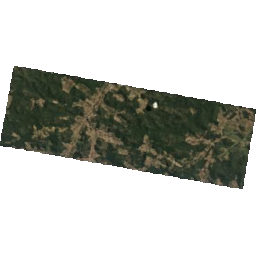

### 2016-08-16 12:57:18 UTC — 20160816_125718_0e0d

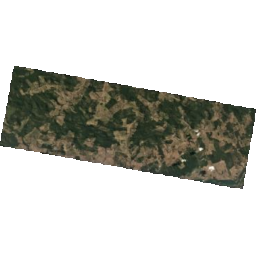

### 2016-08-16 12:57:19 UTC — 20160816_125719_0e0d

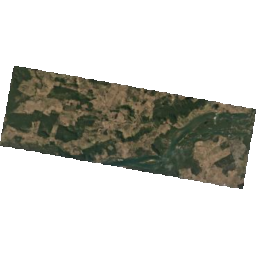

### 2016-08-16 12:58:16 UTC — 20160816_125816_0e0f

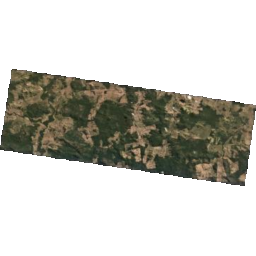

### 2016-08-16 12:58:17 UTC — 20160816_125817_0e3a

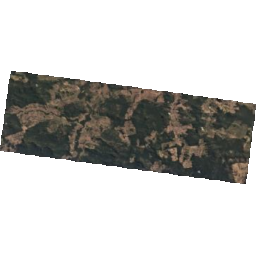

### 2016-08-16 12:58:17 UTC — 20160816_125817_0e0f

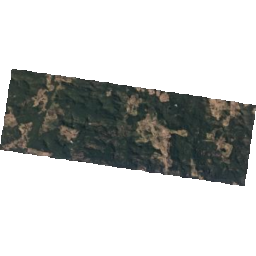

### 2016-08-16 12:58:18 UTC — 20160816_125818_0e0f

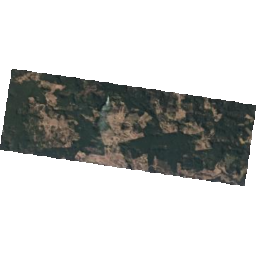

### 2016-08-16 12:58:19 UTC — 20160816_125819_0e3a

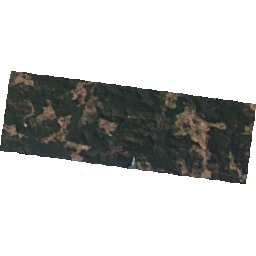

### 2016-08-16 12:58:19 UTC — 20160816_125819_0e0f

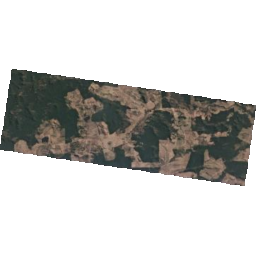

### 2016-08-16 12:58:20 UTC — 20160816_125820_0e3a

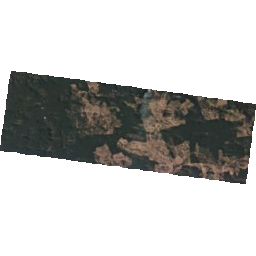

### 2016-08-16 12:58:21 UTC — 20160816_125821_0e0f

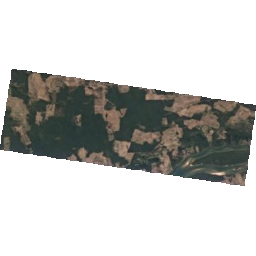

### 2016-08-16 12:58:21 UTC — 20160816_125821_0e3a

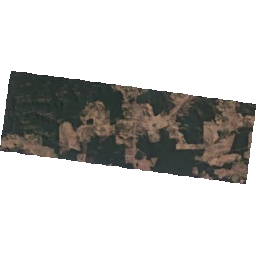

### 2016-08-16 12:58:28 UTC — 20160816_125828_0e16

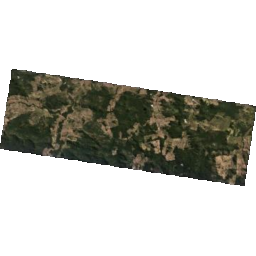

### 2016-08-16 12:58:29 UTC — 20160816_125829_0e16

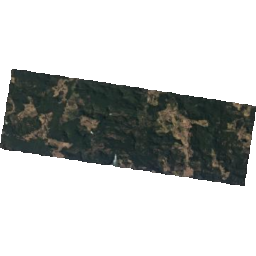

### 2016-08-16 12:58:31 UTC — 20160816_125831_0e16

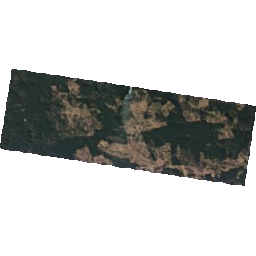

### 2016-08-16 12:58:32 UTC — 20160816_125832_0e16

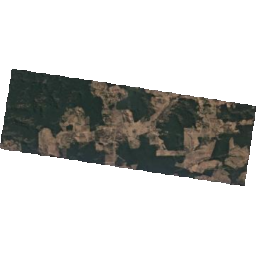

### 2017-06-22 13:00:57 UTC — 20170622_130057_1026

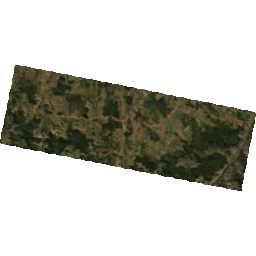

### 2017-06-22 13:00:58 UTC — 20170622_130058_1026

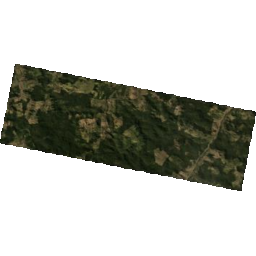

### 2017-06-22 13:01:00 UTC — 20170622_130100_1026

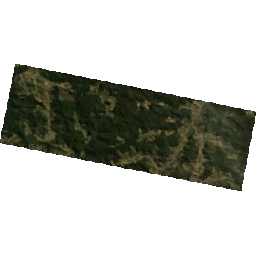

### 2017-06-22 13:01:01 UTC — 20170622_130101_1026

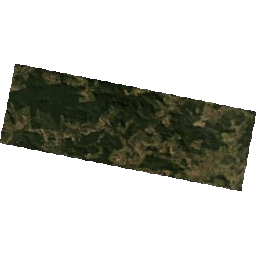

### 2017-06-22 13:01:02 UTC — 20170622_130102_1026

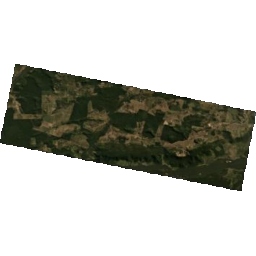

### 2017-06-22 13:01:48 UTC — 20170622_130148_1024

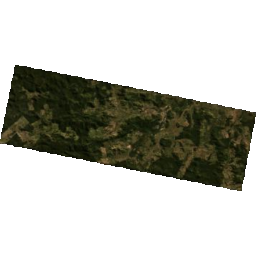

### 2017-06-22 13:01:49 UTC — 20170622_130149_1024

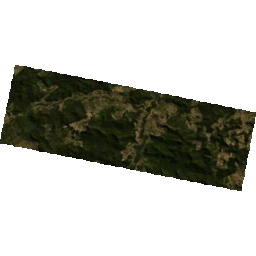

### 2017-06-22 13:01:51 UTC — 20170622_130151_1024

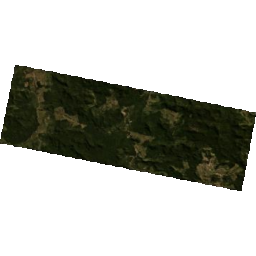

### 2017-06-22 13:01:52 UTC — 20170622_130152_1024

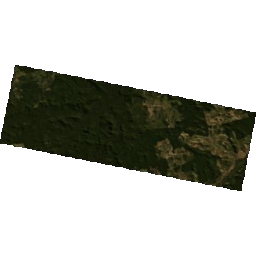

### 2017-06-22 13:01:53 UTC — 20170622_130153_1024

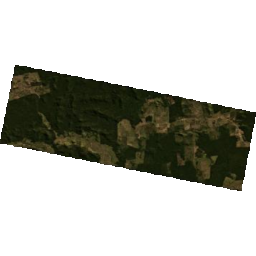

### 2020-07-09 13:14:51 UTC — 20200709_131451_0e19

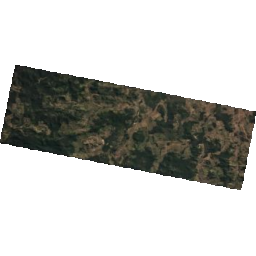

### 2020-07-09 13:14:52 UTC — 20200709_131452_0e19

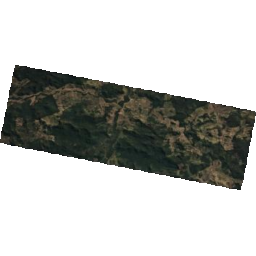

### 2020-07-09 13:14:53 UTC — 20200709_131453_0e19

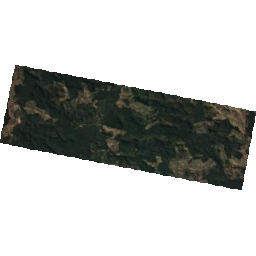

### 2020-07-09 13:14:54 UTC — 20200709_131454_0e19

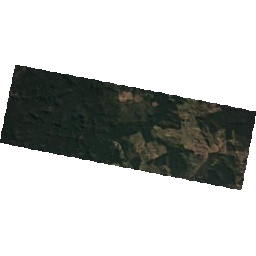

### 2020-07-09 13:14:55 UTC — 20200709_131455_0e19

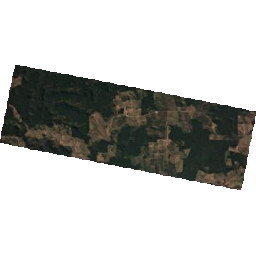

### 2020-07-09 13:42:56 UTC — 20200709_134256_01_105c

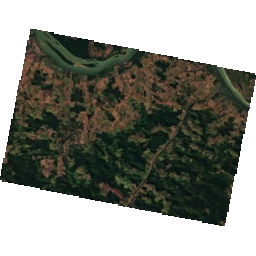

### 2020-07-09 13:42:57 UTC — 20200709_134257_89_105c

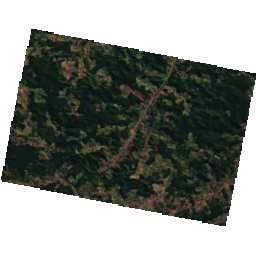

### 2020-07-09 13:42:59 UTC — 20200709_134259_76_105c

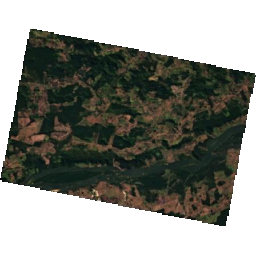

### 2021-06-22 13:00:16 UTC — 20210622_130016_76_2440

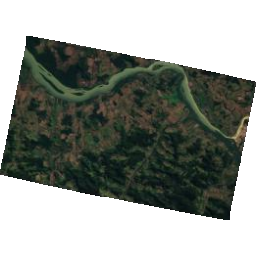

### 2021-06-22 13:00:19 UTC — 20210622_130019_06_2440

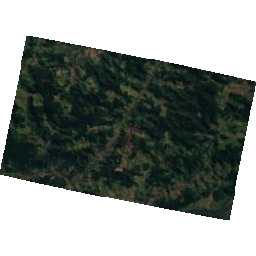

### 2021-06-22 13:00:21 UTC — 20210622_130021_37_2440

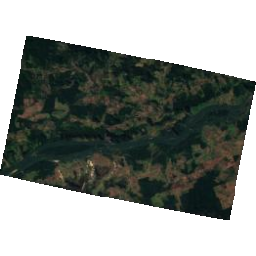

### 2021-06-22 13:01:36 UTC — 20210622_130136_01_2429

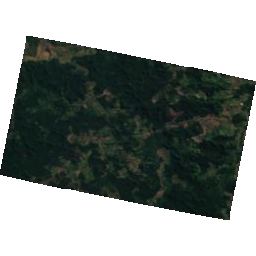

### 2021-06-22 13:01:38 UTC — 20210622_130138_31_2429

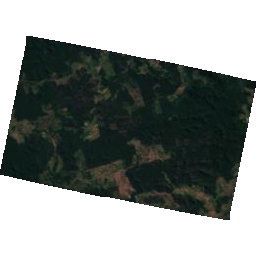

### 2021-06-22 13:50:08 UTC — 20210622_135008_90_2419

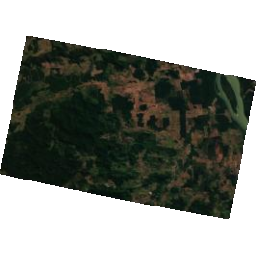

### 2021-06-22 13:50:11 UTC — 20210622_135011_38_2419

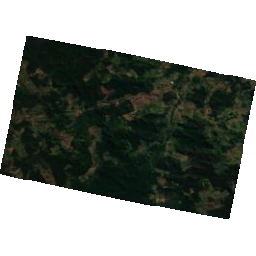

### 2021-06-22 13:50:13 UTC — 20210622_135013_86_2419

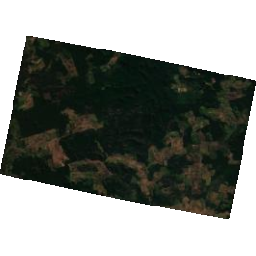

### 2022-07-05 12:55:42 UTC — 20220705_125542_65_242d

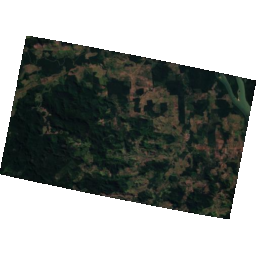

### 2022-07-05 12:55:44 UTC — 20220705_125544_94_242d

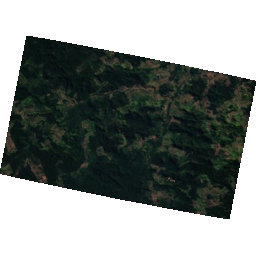

### 2022-07-05 12:55:47 UTC — 20220705_125547_24_242d

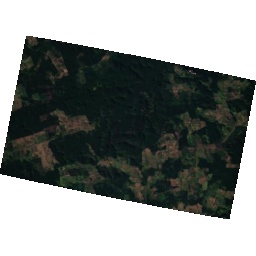

### 2022-07-05 13:26:56 UTC — 20220705_132656_22_2482

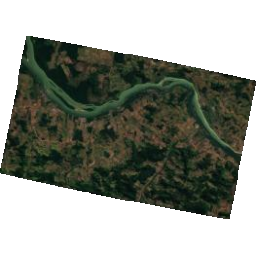

### 2022-07-05 13:26:58 UTC — 20220705_132658_50_2482

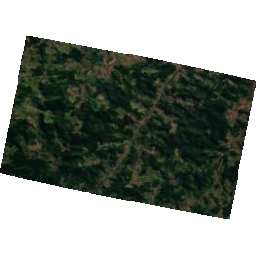

### 2022-07-05 13:27:00 UTC — 20220705_132700_78_2482

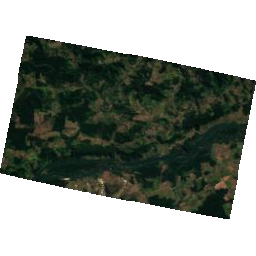

### 2023-06-25 13:30:59 UTC — 20230625_133059_08_2438

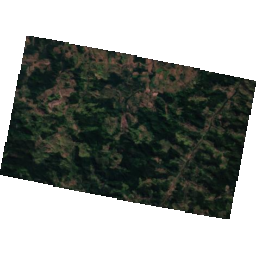

### 2023-06-25 13:31:01 UTC — 20230625_133101_19_2438

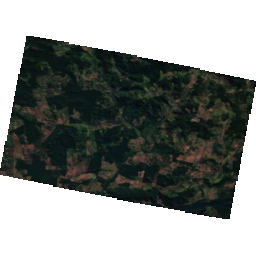

### 2023-06-25 13:31:03 UTC — 20230625_133103_30_2438

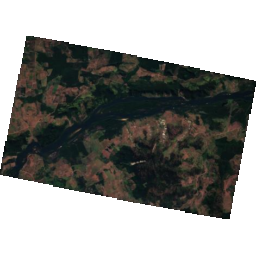

### 2023-06-25 13:31:50 UTC — 20230625_133150_27_2495

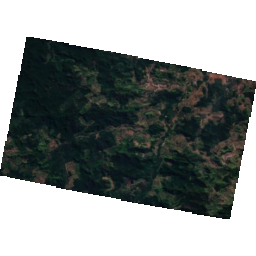

### 2023-06-25 13:31:52 UTC — 20230625_133152_41_2495

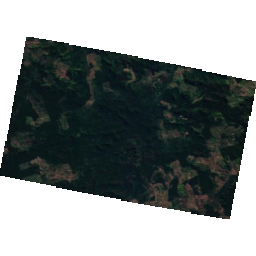

### 2023-06-25 13:31:54 UTC — 20230625_133154_55_2495

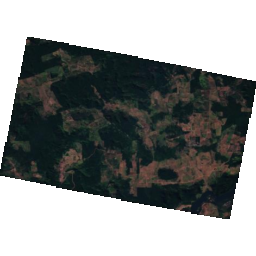

### 2024-07-29 13:58:11 UTC — 20240729_135811_12_24f5

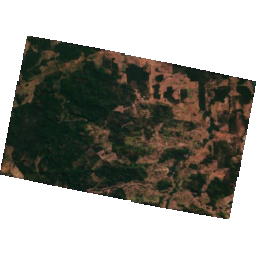

### 2024-07-29 13:58:13 UTC — 20240729_135813_35_24f5

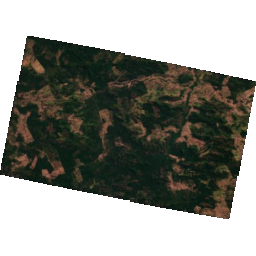

### 2024-07-29 13:58:15 UTC — 20240729_135815_59_24f5

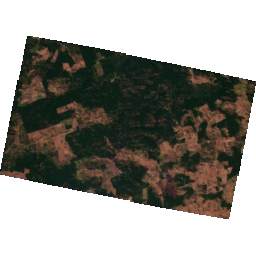

### 2024-07-29 13:59:49 UTC — 20240729_135949_11_24e0

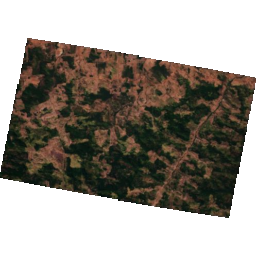

### 2024-07-29 13:59:51 UTC — 20240729_135951_35_24e0

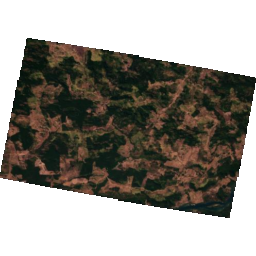

### 2024-07-29 13:59:53 UTC — 20240729_135953_59_24e0

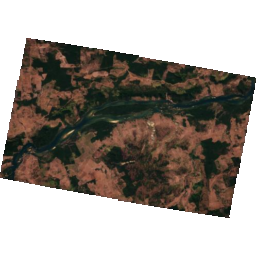

### 2025-07-21 14:11:53 UTC — 20250721_141153_79_251c

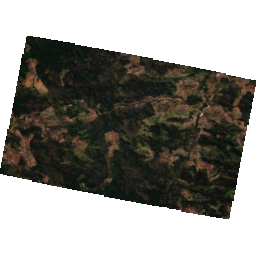

### 2025-07-21 14:11:56 UTC — 20250721_141156_03_251c

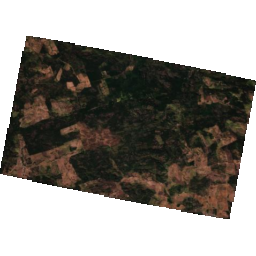

### 2025-07-21 14:16:40 UTC — 20250721_141640_52_252e

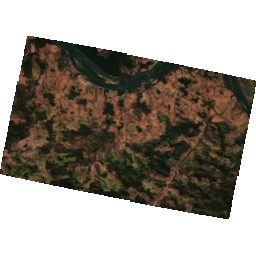

### 2025-07-21 14:16:42 UTC — 20250721_141642_63_252e

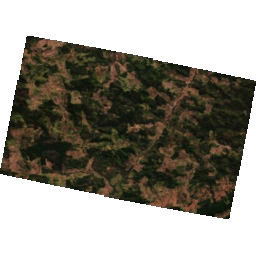

### 2025-07-21 14:16:44 UTC — 20250721_141644_73_252e

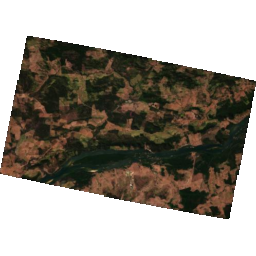

### 2026-08-02 13:50:33 UTC — 20260802_135033_78_254d

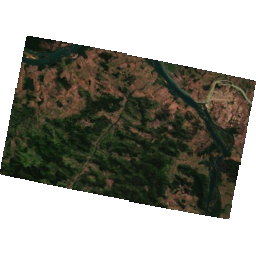

### 2026-08-02 13:50:35 UTC — 20260802_135035_88_254d

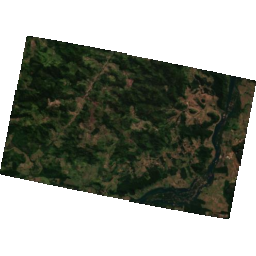

### 2026-08-02 13:50:37 UTC — 20260802_135037_98_254d

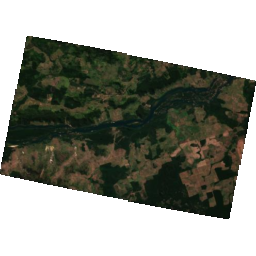

### 2026-08-02 14:27:22 UTC — 20260802_142722_38_253d

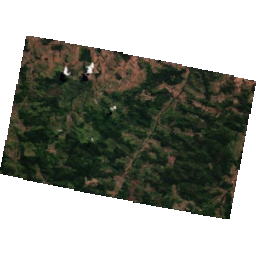

### 2026-08-02 14:27:24 UTC — 20260802_142724_35_253d

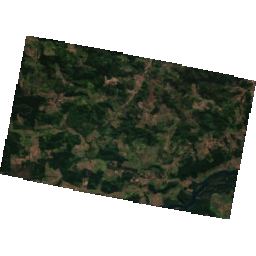

### 2026-08-02 14:27:26 UTC — 20260802_142726_32_253d

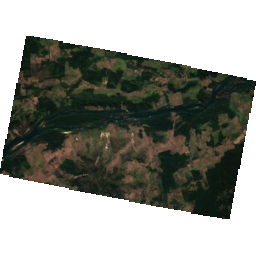

### 2026-08-02 14:34:48 UTC — 20260802_143448_16_2409

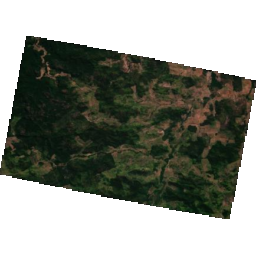

### 2026-08-02 14:34:49 UTC — 20260802_143449_97_2409

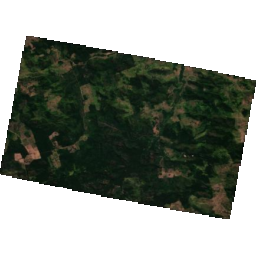

### 2026-08-02 14:34:51 UTC — 20260802_143451_78_2409

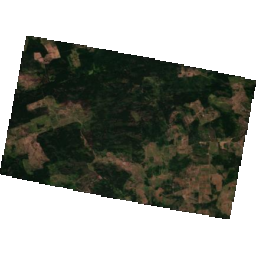

### 2026-08-02 14:36:17 UTC — 20260802_143617_56_24db

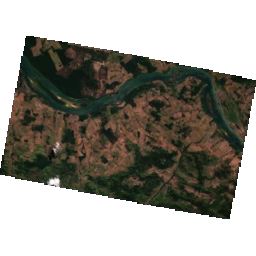

### 2026-08-02 14:36:21 UTC — 20260802_143621_57_24db

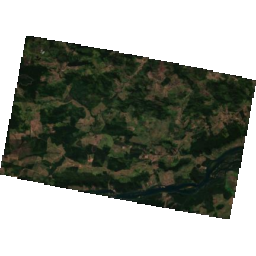

In [6]:
if not scenes.empty:
    selected = scenes.set_index("id", drop=False)
    missing = [i for i in REQUESTED_SCENE_IDS if i not in selected.index]
    if missing:
        print(f"{len(missing)} requested IDs were not returned by this search; they may be unavailable to this account or outside the AOI.")

    for scene_id in REQUESTED_SCENE_IDS:
        if scene_id not in selected.index:
            continue
        row = selected.loc[scene_id]
        if isinstance(row, pd.DataFrame):  # duplicated id
            row = row.iloc[0]
        if pd.isna(row["thumbnail"]) or not row["thumbnail"]:
            print(f"Preview unavailable for {scene_id}: no thumbnail link was returned.")
            continue

        acquired = pd.to_datetime(row["acquired"], utc=True, errors="coerce")
        if pd.notna(acquired):
            title_time = acquired.strftime("%Y-%m-%d %H:%M:%S UTC")
        else:
            try:
                title_time = pd.to_datetime(scene_id[:15], format="%Y%m%d_%H%M%S").strftime("%Y-%m-%d %H:%M:%S") + " (UTC, from scene ID)"
            except ValueError:
                title_time = "Acquisition time unavailable"

        display(Markdown(f"### {title_time} — {scene_id}"))
        try:
            thumb = requests.get(row["thumbnail"], auth=(PLANET_API_KEY, ""), timeout=(15, 60))
            thumb.raise_for_status()
            display(Image(data=thumb.content, width=600))
        except requests.RequestException as exc:
            print(f"Preview unavailable for {scene_id}: {exc}")

# Please continue to Notebook --> "2_planet_data_preparatioin_sentinelhub.ipynb"